In [1]:
from pathlib import Path

import pandas as pd
import geopandas as gpd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
import matplotlib.patheffects as pe

BASIS = Path("../../data/algemeen/gis")
MAPPEN = {"wijken": BASIS / "wijken",
          "straten": BASIS / "straten",
          "bebouwing": BASIS / "bebouwing",
          "infrastructuur": BASIS / "infrastructuur"}
UITVOER = Path("../../fig/H6")
UITVOER.mkdir(parents=True, exist_ok=True)

CRS = "EPSG:31370"                       
GEO = (".shp", ".gpkg", ".geojson")


def laad(map_, wat, jaar):
    """Bestandsnaam wat_jaar, waarbij jaar ook een periode kan zijn (1874-1886)."""
    treffers = [p for p in sorted(MAPPEN[map_].glob(f"{wat}_{jaar}*"))
                if p.suffix.lower() in GEO]
    if not treffers:
        raise FileNotFoundError(f"{wat}_{jaar} niet gevonden in {MAPPEN[map_]}")
    if len(treffers) > 1:
        print(f"let op: meerdere bestanden voor {wat}_{jaar}, "
              f"gekozen: {treffers[0].name}")
    return gpd.read_file(treffers[0]).to_crs(CRS)


for map_, pad in MAPPEN.items():
    print(map_ + ":", ", ".join(sorted(p.stem for p in pad.glob("*")
                                       if p.suffix.lower() in GEO)))

wijken: ._wijken_1874-1886, ._wijken_1886-1901, ._wijken_1901-1920, ._wijken_1921-1944, wijken_1874-1886, wijken_1886-1901, wijken_1901-1920, wijken_1921-1944
straten: ._1898_Street, ._1898_straatzijden, 1898_Street, 1898_straatzijden
bebouwing: ._bebouwing_1886, ._bebouwing_1908, ._vesting_1886, ._vesting_1908, ._water_1886, ._water_1908, bebouwing_1886, bebouwing_1908, vesting_1886, vesting_1908, water_1886, water_1908
infrastructuur: ._danszalen_1898, ._danszalen_1925, ._elektrischeverlichting_1903, ._elektrischeverlichting_1921, ._gasverlichting_1889, ._gasverlichting_1919, ._herbergen_1898, ._paardentram_1895, ._parken_en_openbarewandelingen_1894, ._treinstations_1885 2, danszalen_1898, danszalen_1925, elektrischetram_1903, elektrischeverlichting_1903, elektrischeverlichting_1921, gasverlichting_1889, gasverlichting_1919, herbergen_1898, paardentram_1895, parken_en_openbarewandelingen_1894, politiekantoren_na1919, politiekantoren_voor1900, treinstations_1885, treinstations_1885 2


In [2]:
TEKST_BREEDTE = 108 / 25.4  # breedte van een afbeelding in het proefschrift (108 mm)
CORPS = 10           # lettergrootte van as-, legenda- en titeltekst (pt)
CORPS_KLEIN = 8.5    # lettergrootte van dichte labels en annotaties (pt)

# ── vaste kleuren per betekenis (gelijk in alle hoofdstukken) ─────────────
KLEUR_HOOFD = "#1A8259"                         # één reeks
KLEUR_VROEG, KLEUR_LAAT = "#A07FD8", "#1A8259"  # vroege / late periode
KLEUR_MIDDEN = "#E07B28"                        # tussenperiode (bij drie periodes)
KLEUR_DAG, KLEUR_NACHT = "#C98A3C", "#2A62A8"
KLEUR_MAN, KLEUR_VROUW = "#E100A3", "#3FB3CC"
KLEUR_WIJK = {1: "#2A62A8", 3: "#E07B28", 5: "#1BAF7A", 6: "#C2187F"}  # 5 = 5+11, 6 = 6+7

mpl.rcParams.update({
    "font.family": "serif",
    "font.serif": ["Libertinus Serif"],
    "font.size": CORPS,
    "axes.titlesize": CORPS,
    "figure.facecolor": "white",
    "savefig.bbox": "tight",
    "savefig.pad_inches": 0.01,
})

TEKST_HOOGTE = 185 / 25.4

KLEUR_STAD = "#c8c8c8"          
KLEUR_BEBOUWING = "#e2e2e2"  
KLEUR_WATER = "#c8d8e8"
KLEUR_GRENS = "#1a1a1a"
KLEUR_LABEL = "#1a1a1a"

KLEUR_GAS = "#C98A3C"          
KLEUR_ELEKTRISCH = KLEUR_HOOFD

LIJN_GRENS = 1.1
LIJN_VESTING = 1.0
CORPS_LABEL = CORPS          # wijknummers
CORPS_SCHAAL = CORPS_KLEIN   # schaalbalk en noordpijl
              
STIP = (0, (1, 1.4))            
GROOTTE_PUNT = 1.2


def meter_in_asfractie(ax, lengte_m):
    """Hoeveel van de asbreedte beslaat lengte_m? Nodig door aspect='equal'."""
    inv = ax.transAxes.inverted()
    p0 = inv.transform(ax.transData.transform((0, 0)))
    p1 = inv.transform(ax.transData.transform((lengte_m, 0)))
    return p1[0] - p0[0]


def schaalbalk(ax, lengte_m=2000, links=0.02, onder=0.06):
    lengte = meter_in_asfractie(ax, lengte_m)
    ax.plot([links, links + lengte], [onder, onder], transform=ax.transAxes,
            color=KLEUR_GRENS, linewidth=1.8, solid_capstyle="butt",
            clip_on=False, zorder=8)
    ax.text(links + lengte / 2, onder + 0.008, f"{lengte_m / 1000:.0f} km",
            transform=ax.transAxes, ha="center", va="bottom",
            fontsize=CORPS_SCHAAL, color=KLEUR_GRENS, clip_on=False, zorder=8)


def noordpijl(ax, links=0.02, onder=0.14, hoogte=0.07):
    ax.annotate("", xy=(links, onder + hoogte), xytext=(links, onder),
                xycoords=ax.transAxes, textcoords=ax.transAxes,
                annotation_clip=False, zorder=8,
                arrowprops=dict(arrowstyle="-|>", color=KLEUR_GRENS,
                                linewidth=1.2, mutation_scale=12))
    ax.text(links, onder + hoogte + 0.012, "N", transform=ax.transAxes,
            ha="center", va="bottom", fontsize=CORPS_SCHAAL,
            color=KLEUR_GRENS, clip_on=False, zorder=8)

# ── eenvormige rasterlijnen in alle figuren ───────────────────────────────
import matplotlib as mpl
mpl.rcParams.update({
    "axes.grid": False,          # raster alleen waar het expliciet aangezet wordt
    "axes.axisbelow": True,      # raster achter de data
    "grid.color": "#96999B",
    "grid.linewidth": 0.4,
    "grid.alpha": 0.5,
    "grid.linestyle": "-",
})


In [3]:
AFBEELDING = {1885: "6.6", 1921: "6.7"}

MOMENTEN = {
    1885: {"wijken": 1886, "bebouwing": 1886, "water": 1886, "vesting": 1886},
    1921: {"wijken": 1921, "bebouwing": 1908, "water": 1908, "vesting": 1908},
}


def vind_nr_col(gdf):
    for k in ["SectionNr", "Section_Nr", "SECTIONNR", "wijk", "WIJK", "wijknr",
              "WIJKNR", "nr", "NR", "nummer", "NUMMER", "id", "ID"]:
        if k in gdf.columns:
            return k
    raise KeyError(f"Geen wijkkolom gevonden. Kolommen: {list(gdf.columns)}")


def laad_wijken(startjaar):
    gdf = laad("wijken", "wijken", startjaar)
    gdf["wijk"] = pd.to_numeric(gdf[vind_nr_col(gdf)], errors="coerce").astype("Int64")
    gdf["centroid"] = gdf.geometry.representative_point()
    return gdf


def selecteer_water(water, min_ha=3.0):
    """Houdt alle waterlichamen boven min_ha (Schelde, dokken)."""
    w = water.explode(index_parts=False).reset_index(drop=True)
    return w[w.geometry.area / 1e4 >= min_ha]


wijken, achtergrond = {}, {}
for moment, cfg in MOMENTEN.items():
    wijken[moment] = laad_wijken(cfg["wijken"])
    lagen = {wat: laad("bebouwing", wat, cfg[wat])
             for wat in ("bebouwing", "water", "vesting")}
    lagen["water"] = selecteer_water(lagen["water"])
    achtergrond[moment] = lagen
    print(f"{moment}: {len(wijken[moment])} wijken, "
          + ", ".join(f"{n} {len(l)}" for n, l in lagen.items()))

1885: 9 wijken, bebouwing 1745, water 19, vesting 16
1921: 12 wijken, bebouwing 2090, water 17, vesting 41


In [4]:
VERLICHTING = {
    1885: {"gas": 1889, "elektrisch": None},   
    1921: {"gas": 1919, "elektrisch": 1921},
}

BESTAND = {"gas": "gasverlichting", "elektrisch": "elektrischeverlichting"}

verlichting = {
    moment: {soort: (laad("infrastructuur", BESTAND[soort], jaar) if jaar else None)
             for soort, jaar in soorten.items()}
    for moment, soorten in VERLICHTING.items()
}

for moment, soorten in verlichting.items():
    for soort, gdf in soorten.items():
        stand = "-" if gdf is None else f"{len(gdf)} × {gdf.geom_type.iloc[0]}"
        print(f"{moment} {soort}: {stand}")

1885 gas: 111 × LineString
1885 elektrisch: -
1921 gas: 427 × LineString
1921 elektrisch: 13 × LineString


In [5]:
lagen_mee = [wijken[m].geometry for m in MOMENTEN]
for m in MOMENTEN:
    lagen_mee += [achtergrond[m][n].geometry for n in ("bebouwing", "vesting")]

alles = gpd.GeoSeries(pd.concat(lagen_mee), crs=CRS)
xmin, ymin, xmax, ymax = alles.total_bounds
marge = 0.02 * max(xmax - xmin, ymax - ymin)
xmin, xmax = xmin - marge, xmax + marge
ymin, ymax = ymin - marge, ymax + marge
print(f"{(xmax - xmin) / 1000:.1f} × {(ymax - ymin) / 1000:.1f} km")

6.8 × 9.8 km


1885: 108 × 175 mm


1921: 108 × 175 mm


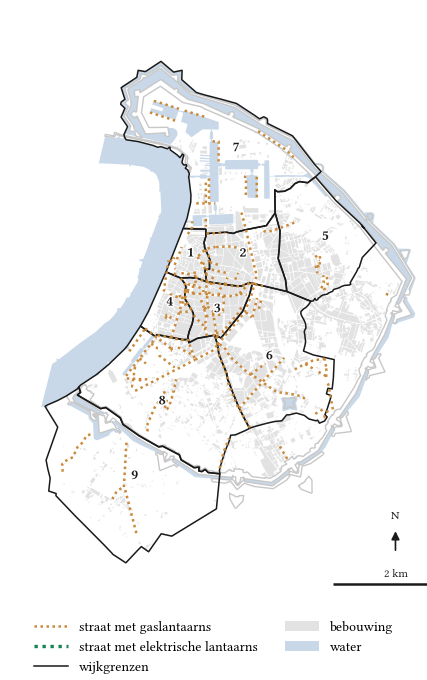

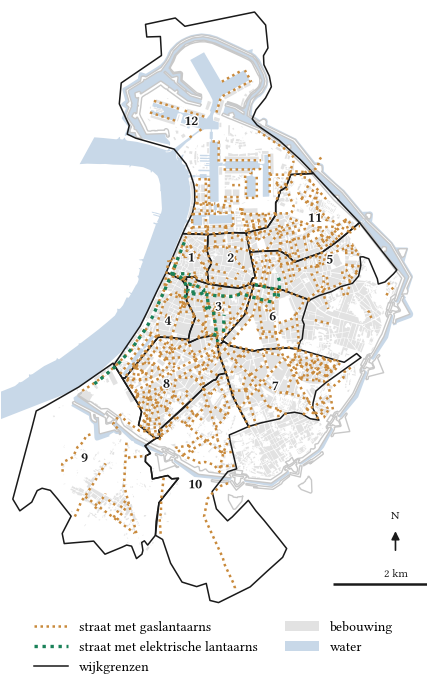

In [6]:
TOON_BEBOUWING = True
LEGENDERUIMTE = 0.75

def teken_verlichting(ax, gdf, kleur, zorder=6, soort="gas"):
    if gdf is None or gdf.empty:
        return
    if soort == "elektrisch":
        gdf.plot(ax=ax, color=kleur, linewidth=2.4, linestyle=STIP, zorder=zorder)
    elif gdf.geom_type.str.contains("Point").all():
        gdf.plot(ax=ax, color=kleur, markersize=GROOTTE_PUNT, linewidth=0,
                 zorder=zorder)
    else:
        gdf.plot(ax=ax, color=kleur, linewidth=1.8, linestyle=STIP, zorder=zorder)


def maak_kaart(moment):
    verhouding = (ymax - ymin) / (xmax - xmin)
    breedte = min(TEKST_BREEDTE, (TEKST_HOOGTE - LEGENDERUIMTE) / verhouding)
    hoogte = breedte * verhouding + LEGENDERUIMTE

    fig, ax = plt.subplots(figsize=(breedte, hoogte))
    fig.subplots_adjust(left=0, right=1, top=1, bottom=LEGENDERUIMTE / hoogte)

    lagen = achtergrond[moment]
    gdf = wijken[moment]

    if TOON_BEBOUWING:
        lagen["bebouwing"].plot(ax=ax, color=KLEUR_BEBOUWING, edgecolor="none",
                                linewidth=0, zorder=1)
    lagen["water"].plot(ax=ax, color=KLEUR_WATER, edgecolor="none",
                        linewidth=0, zorder=2)
    lagen["vesting"].plot(ax=ax, color="none", edgecolor=KLEUR_STAD,
                          linewidth=LIJN_VESTING, zorder=3)
    gdf.plot(ax=ax, facecolor="none", edgecolor=KLEUR_GRENS,
             linewidth=LIJN_GRENS, zorder=4)

    for _, rij in gdf.iterrows():
        if pd.isna(rij["wijk"]):
            continue
        ax.annotate(int(rij["wijk"]), xy=(rij["centroid"].x, rij["centroid"].y),
                    ha="center", va="center", fontsize=CORPS_LABEL,
                    fontweight="bold", color=KLEUR_LABEL, zorder=7,
                    path_effects=[pe.withStroke(linewidth=2.2, foreground="white")])

    for soort, kleur, z in (("gas", KLEUR_GAS, 6),
                            ("elektrisch", KLEUR_ELEKTRISCH, 8)):
        teken_verlichting(ax, verlichting[moment][soort], kleur, z, soort)

    ax.set_xlim(xmin, xmax)
    ax.set_ylim(ymin, ymax)
    ax.set_aspect("equal")
    ax.set_axis_off()

    legende = [
        Line2D([], [], color=KLEUR_GAS, linestyle=STIP, linewidth=1.8,
               label="straat met gaslantaarns"),
        Line2D([], [], color=KLEUR_ELEKTRISCH, linestyle=STIP, linewidth=2.4,
               label="straat met elektrische lantaarns"),
        Line2D([], [], color=KLEUR_GRENS, linewidth=LIJN_GRENS, label="wijkgrenzen"),
        Patch(facecolor=KLEUR_BEBOUWING, edgecolor="none", label="bebouwing"),
        Patch(facecolor=KLEUR_WATER, edgecolor="none", label="water"),
    ]
    fig.legend(handles=legende, loc="lower center", ncol=2, frameon=False,
               fontsize=CORPS, handlelength=2.4, columnspacing=2.0,
               bbox_to_anchor=(0.5, 0.005))

    fig.canvas.draw()
    BALK_LINKS, BALK_ONDER = 0.78, 0.05
    schaalbalk(ax, links=BALK_LINKS, onder=BALK_ONDER)
    noordpijl(ax, links=BALK_LINKS + meter_in_asfractie(ax, 2000) / 2,
              onder=BALK_ONDER + 0.05, hoogte=0.04)

    fig.savefig(UITVOER / f"{AFBEELDING[moment]}_straatverlichting_{moment}.png", dpi=300)
    print(f"{moment}: {breedte * 25.4:.0f} × {hoogte * 25.4:.0f} mm")
    return fig


for moment in MOMENTEN:
    maak_kaart(moment)
plt.show()